# Import the necessery libraries

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Perceptron class

This perceptron is a simple perceptron with a constant learning rate.

In [6]:
class simple_perceptron :
    def __init__(self, learning_rate: float = 0.1, epochs: int = 1000):
        """
        epochs must be <= the number of rows of x_train.
        """
        self.weights = None # the final weights of the perceptron/line after the training.
        self.bias = None # the final bias of the perceptron/line after the training.
        self.lr: float = learning_rate
        self.epochs: int = epochs

    def positive_or_negative_region(self, weighted_sum: np.float64 | np.ndarray):
        return (weighted_sum > 0).astype(int)

    def fit(self, x_train: np.ndarray, y_train: np.ndarray):
        n, m = x_train.shape # 800 rows, 2 input columns.
        a_2d_table_with_n_row_1_column = np.ones(shape=(n, 1))
        x_train = np.hstack((x_train, a_2d_table_with_n_row_1_column)) # both have same number of rows, n for hstack() to work.
        m += 1 # Now its 3 INPUT columns since above we added a column filled with 1 for bias as the last column).
        current_weights_and_bias = np.ones(shape=(m), dtype=np.float64) # Current Line means "current_weights_and_bias".

        random_indices = np.random.permutation(self.epochs) # no duplicate indices here i.e. the algo picks unique index each time.
        for random_index in random_indices:
            # i) pick a random input x and its y :
            x, y = x_train[random_index], y_train[random_index] # In x, remember again the last column with 1 is for bias.
            # ii) predict for this input in terms of the current line :
            weighted_sum = np.dot(current_weights_and_bias, x) # Output is a np.float64 type.
            y_hat = self.positive_or_negative_region(np.asarray([weighted_sum])) [0]
            # iii) correct|rotate_and_slide the line (i.e. weights and bias) if misclassified for x, otherwise keep the line as it was :
            current_weights_and_bias = current_weights_and_bias + (y - y_hat) * self.lr * x

        self.weights, self.bias = current_weights_and_bias[:-1], current_weights_and_bias[-1]

    def predict(self, x_test: np.ndarray):
        if len(x_test.shape) == 1:
            print("x_test must be 2D Array")
            return None
        
        weighted_sum = np.dot(x_test, self.weights) + self.bias # (n,2) dot (2) -> (n). If it was the other way, np.dot won't work.
        return self.positive_or_negative_region(weighted_sum)


# Training, testing, drawing the perceptron/line on the graph along input dataset

In [7]:

# create/import the dataset, split the dataset in the way we want :
X, y = make_classification(n_samples=100, n_features=2, n_informative=1, n_redundant=0,
                            n_classes=2, n_clusters_per_class=1, random_state=41, hypercube=False, class_sep=15)

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

print(type(X), type(y_train))

<class 'numpy.ndarray'> <class 'numpy.ndarray'>


Weights = [1.20329183 0.45174066]
Bias = 1.1
Total wrong predictions = 0
x_intercept, y_intercept [-0.91, 0], [0, -2.44]


<Axes: >

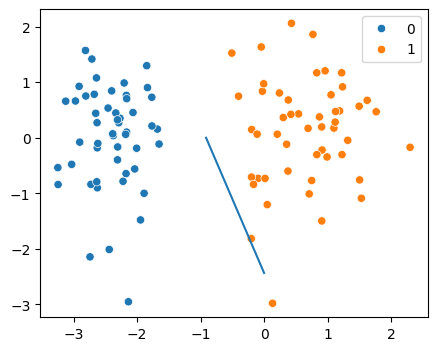

In [10]:
# fit/train the model and check the error it made by predicting on x_test :
perceptron = simple_perceptron(epochs = int(x_train.shape[0] * 0.7)) # training on 70% inputs(rows).
perceptron.fit(x_train, y_train)

print(f"Weights = {perceptron.weights}")
print(f"Bias = {perceptron.bias}")

predicted_y_test = perceptron.predict(x_test)
print("Total wrong predictions =", np.abs(y_test - predicted_y_test).sum())

plt.figure(figsize=(5, 4))
sns.scatterplot(x = X[:, 0], y = X[:, 1], hue=y)

A, B, b = perceptron.weights[0], perceptron.weights[1], perceptron.bias
round_list = lambda any_list: list(map(lambda v: round(v, 2), any_list))
x_intercept, y_intercept = [-b/A, 0], [0, -b/B]
print(f"x_intercept, y_intercept {round_list(x_intercept)}, {round_list(y_intercept)}")

sns.lineplot(x = x_intercept, y = y_intercept)

But as you can see the height and width of the perceptron|line is short on the above seaborn graph especially the height. So the line needs to extend all the way up to maximum y axis value and down to minimum y axis. To extend the line to maximum and minimum y axis, we need to know how steep the line is, which direction it goes i.e. how much changes happen in y axis when x changes. And this is slope. Remember y = mx + b which is also a line equation and another form of line is Ax + By + C = 0. Now you know y = [y.min(), y.max()]. Just find x. (below code section)

But there is another possibility where the positive and negative regions can be up down instead of left right, "extend_till_y.png" in this same folder. Here if you keep extend the line, it will hit the both maximum and minimum y axis values even though in this png I've not shown the line hitting on minimum y axis values intentionally. Now all we've to do is finding the x values for y.max() and y.min(). But this would be a very big graph (The graph in extend_till_hits_y.png) where seaborn/matplotlib will show the inputs in small area. Ultimately the graph will appear bad.

So we've to tell the matplotlib to display the graph within x.min() to x.max() and y.min() to y.max() i.e. limiting both axis. Since y values are here y.min() and y.max() but x values (for these y axis values) can be outside x.min() and x.max(), so we only limit the x axis. 

In this above approch where we extend the line till it hits y.max() and y.min() values, and then limiting the x axis; we can also say "extend the line till it hits x.max() and x.min() values and find the y axis values which may go outside of y.min() and y.max() range, so limit y axis only for better visual readability", "extend_till_hits_x.png" in this same folder.

[-2.98092432  2.0615874 ] [ 0.20494173 -1.68812154]


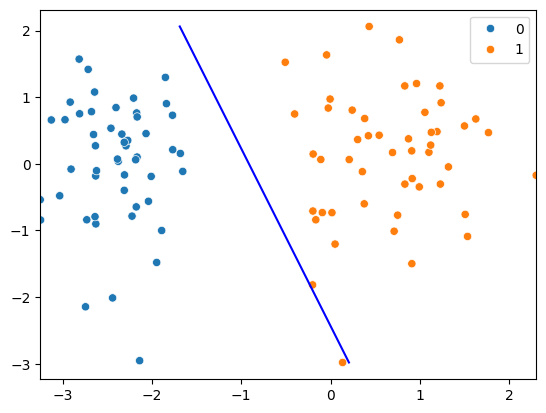

In [11]:
# Draw the whole perceptron line on the whole y axis :
m = -perceptron.weights[0] / perceptron.weights[1] # -A/B
b = -perceptron.bias / perceptron.weights[1] # -bias/B

y_axis_values = np.asarray([X[:, 1].min(), X[:, 1].max()]) # X[:, 1] = The whole 2nd column, y.
x_axis_values = (y_axis_values - b) / m

sns.scatterplot(x = X[:, 0], y = X[:, 1], hue=y)
sns.lineplot(x = x_axis_values, y = y_axis_values, color="blue")
plt.xlim(left=X[:, 0].min(), right=X[:, 0].max()) # Only limit the x axis since only x axis values can be outside of x.min() and x.max().
                                                  # Not y axis, since y axis is always within y.min() and y.max() range.

print(y_axis_values, x_axis_values)